UE Data Mining - Projet (2026-2027)
Nom du groupe : G10
Membres du groupe :
    Mahamoud Guedi IDIL


Partie 1 — Data Cleaning, Exploration et Corrélations : Dossier Health

1.1. Introduction et Objectifs du Dossier Health

Le dossier data/health/ regroupe 7 jeux de données issus des systèmes hospitaliers (SYS-CLN-OPS), des moniteurs cardiaques (SYS-CLN-DEV) et des archives de comptes-rendus médicaux (SYS-DOC-CLN).

L'objectif de ce notebook est triple :
1. Auditer et nettoyer chaque table : Supprimer les doublons d'enregistrement, corriger les erreurs typographiques (espaces multiples, casse incohérente), uniformiser les formats de dates au standard ISO et sauver les valeurs numériques corrompues (virgules décimales et unités concaténées dans les champs numériques).
2. Exporter les 7 jeux de données propres dans data_cleaned/health/ pour permettre les croisements inter-domaines ultérieurs.
3. Construire un Panel Patient unifié (240 patients) et analyser la Matrice de Corrélation, une ACP (PCA), un Clustering K-Means , une Analyse Spectrale FFT des signaux ECG et une Analyse TF-IDF des notes cliniques pour faire émerger le secret médical caché dans ces données.

In [1]:
# 1. IMPORTATION DES LIBRAIRIES ET CHARGEMENT DES 7 DATASETS
import pandas as pd
import numpy as np
import re
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Détection automatique du dossier contenant les fichiers CSV
DATA_DIR = Path("..") if Path("..").exists() else Path(".")

# Chargement des 7 tables brutes du dossier health
df_pat = pd.read_csv(DATA_DIR / "patient_administration.csv")
df_enc = pd.read_csv(DATA_DIR / "clinical_encounters.csv")
df_prc = pd.read_csv(DATA_DIR / "clinical_procedures.csv")
df_obs = pd.read_csv(DATA_DIR / "clinical_observations.csv")
df_crd = pd.read_csv(DATA_DIR / "cardiac_recordings.csv")
df_sig = pd.read_csv(DATA_DIR / "cardiac_signal_samples.csv")
df_notes = pd.read_csv(DATA_DIR / "clinical_notes.csv")

# Fonction utilitaire pour nettoyer les colonnes numériques polluées par du texte ou des virgules
def clean_numeric(val):
    """
    Nettoie une valeur numérique :
    - Remplace les virgules françaises par des points décimaux (ex: '84,9' -> '84.9')
    - Supprime les unités collées aux nombres (ex: '82.2 index' -> '82.2', '8.07 L/min' -> '8.07')
    - Convertit le résultat en float (ou None si la valeur est manquante)
    """
    if pd.isna(val):
        return None
    s = str(val).strip()
    # On conserve uniquement les chiffres, virgules, points et signes moins
    s = re.sub(r'[^\d,.\-]', '', s)
    s = s.replace(',', '.')
    try:
        return float(s)
    except ValueError:
        return None

print("Chargement terminé avec succès !")

Chargement terminé avec succès !


1.2. Nettoyage de patient_administration.csv

Cette table est le référentiel des patients (patient_number).L inspection révèle 1 doublon exact (PAT-31045, Olia Garen), 
des espaces doubles dans les professions ("  Regional  executive "),des problèmes de majuscules/minuscules ("vALENNE rEPUBLIC", "ACTIVE") et des dates avec des slashs ("01/09/2019").
    
Nos actions réalisées : Déduplication, normalisation des chaînes de caractères, conversion des dates au format YYYY-MM-DD, et création 
de variables indicatrices (dummies) sur record_status et home_region.


In [2]:
# Observation statistique initiale de la table des patients
df_pat.describe(include="all")

,patient_number,family_name,given_name,date_of_birth,registered_sex,home_region,occupation_text,registration_date,primary_facility_license,record_status
count,241,241,241,241,241,241,241,241,241,241
unique,240,67,67,239,3,6,46,65,3,4
top,PAT-31045,Garen,Taren,1976-07-07,female,Avelora Federation,retired professional,2021-09-01,FAC-VLN-101,active
freq,2,9,10,2,97,54,29,8,151,230


In [3]:
# Vérification et suppression des lignes dupliquées
print("Nombre de doublons dans patient_administration :", df_pat.duplicated().sum())
df_pat = df_pat.drop_duplicates().copy()

# Vérification des valeurs manquantes
print("\nValeurs manquantes par colonne :\n", df_pat.isna().sum())

Nombre de doublons dans patient_administration : 1

Valeurs manquantes par colonne :
 patient_number              0
family_name                 0
given_name                  0
date_of_birth               0
registered_sex              0
home_region                 0
occupation_text             0
registration_date           0
primary_facility_license    0
record_status               0
dtype: int64


In [4]:
# Inspection des valeurs uniques avant nettoyage pour repérer les anomalies de texte
for c in ["home_region", "registered_sex", "record_status"]:
    print(df_pat[c].value_counts(), "\n")

home_region
Avelora Federation      54
Nordhaven Union         52
Valenne Republic        47
Kintara Republic        47
Tembara Commonwealth    39
vALENNE rEPUBLIC         1
Name: count, dtype: int64 

registered_sex
female       96
male         93
nonbinary    51
Name: count, dtype: int64 

record_status
active      229
inactive      9
deceased      1
ACTIVE        1
Name: count, dtype: int64 



In [5]:
# 1. Suppression des espaces en début/fin de chaîne et remplacement des doubles espaces par un espace simple
for c in ["family_name", "given_name", "home_region", "occupation_text", "registered_sex", "record_status"]:
    df_pat[c] = df_pat[c].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)

# 2. Harmonisation de la casse (Majuscules / Minuscules)
df_pat["home_region"] = df_pat["home_region"].str.title()      # Ex: 'vALENNE rEPUBLIC' -> 'Valenne Republic'
df_pat["registered_sex"] = df_pat["registered_sex"].str.lower()
df_pat["record_status"] = df_pat["record_status"].str.lower()  # Ex: 'ACTIVE' -> 'active'

# 3. Uniformisation des dates au format ISO YYYY-MM-DD (corrige les dates avec '/')
for c in ["date_of_birth", "registration_date"]:
    df_pat[c] = pd.to_datetime(df_pat[c], format="mixed", dayfirst=True, errors="coerce").dt.strftime("%Y-%m-%d")

# 4. Encodage catégoriel (One-Hot Encoding via get_dummies) tout en conservant les colonnes d'origine
dummies_status = pd.get_dummies(df_pat["record_status"], prefix="record_status")
dummies_region = pd.get_dummies(df_pat["home_region"], prefix="home_region")
df_pat = pd.concat([df_pat, dummies_status, dummies_region], axis=1)

print(f"Table patient_administration nettoyée : {df_pat.shape[0]} patients uniques.")
df_pat.head()

Table patient_administration nettoyée : 240 patients uniques.


,patient_number,family_name,given_name,date_of_birth,registered_sex,home_region,occupation_text,registration_date,primary_facility_license,record_status,record_status_active,record_status_deceased,record_status_inactive,home_region_Avelora Federation,home_region_Kintara Republic,home_region_Nordhaven Union,home_region_Tembara Commonwealth,home_region_Valenne Republic
0,PAT-31162,Varen,Eli,1962-04-19,male,Valenne Republic,corporate adviser,2018-01-01,FAC-VLN-101,inactive,False,False,True,False,False,False,False,True
1,PAT-31040,Valen,Jonah,1972-12-06,male,Valenne Republic,research professional,2017-01-02,FAC-AVL-201,active,True,False,False,False,False,False,False,True
2,PAT-31115,Oren,Nadia,1979-03-09,female,Valenne Republic,clinical specialist,2018-01-05,FAC-AVL-301,active,True,False,False,False,False,False,False,True
3,PAT-31186,Kader,Soren,1969-11-02,male,Nordhaven Union,corporate adviser,2017-01-06,FAC-VLN-101,active,True,False,False,False,False,True,False,False
4,PAT-31215,Roe,Ilan,1976-07-07,male,Avelora Federation,research professional,2018-01-05,FAC-AVL-201,active,True,False,False,True,False,False,False,False


Conclusion intermédiaire (patient_administration) :

La base compte exactement 240 patients uniques répartis dans 5 régions et rattachés à 3 cliniques (FAC-VLN-101, FAC-AVL-201, FAC-AVL-301).

Les 10 premiers patients (index 0 à 9 : PAT-31162 Eli Varen à PAT-31037 Sel Aran) ont tous des profils de conseillers ou chercheurs, et le patient n°1 (PAT-31162 Eli Varen) est au statut inactive.

Les 8 patients suivants (index 10 à 17 : PAT-31221 Leora Kassen à PAT-31099 Elira Vaun) sont de hauts dirigeants politiques et industriels nés entre 1935 et 1958 (Elira Vaun étant l'unique patiente deceased de la base).


1.3. Nettoyage de clinical_encounters.csv

Cette table trace les consultations médicales. Elle contient 2 doublons exacts (ENC-000846 et ENC-000733), 3 valeurs manquantes dans referral_source, des espaces multiples dans service_unit ("  cardiac  diagnostics ") et des différences de casse qui dédoublent artificiellement les types de visites (15 modalités brutes au lieu de 10).


In [6]:
# Suppression des doublons exacts et traitement des valeurs manquantes
print("Nombre de doublons dans clinical_encounters :", df_enc.duplicated().sum())
df_enc = df_enc.drop_duplicates().copy()

print("\nValeurs manquantes avant traitement :\n", df_enc.isna().sum())
# On remplace les 3 sources d'orientation manquantes par 'unknown'
df_enc["referral_source"] = df_enc["referral_source"].fillna("unknown")

Nombre de doublons dans clinical_encounters : 2

Valeurs manquantes avant traitement :
 encounter_number              0
patient_number                0
encounter_start               0
encounter_end                 0
facility_license_number       0
encounter_type                0
referral_source               3
attending_license_number      0
service_unit                  0
disposition                   0
confidentiality_class         0
follow_up_date              240
dtype: int64


In [7]:
# 1. Normalisation des colonnes textuelles catégorielles (espaces + minuscules)
for c in ["encounter_type", "referral_source", "service_unit", "disposition", "confidentiality_class"]:
    df_enc[c] = df_enc[c].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True).str.lower()

# 2. Uniformisation des dates de début et de fin de visite au format ISO YYYY-MM-DDTHH:MM:SS
for c in ["encounter_start", "encounter_end"]:
    df_enc[c] = pd.to_datetime(df_enc[c], format="mixed", dayfirst=True, errors="coerce").dt.strftime("%Y-%m-%dT%H:%M:%S")

# 3. Uniformisation de la date de suivi (ou 'none' lorsqu'aucun suivi n'est planifié)
df_enc["follow_up_date"] = pd.to_datetime(df_enc["follow_up_date"], format="mixed", dayfirst=True, errors="coerce").dt.strftime("%Y-%m-%d")
df_enc["follow_up_date"] = df_enc["follow_up_date"].fillna("none")

# 4. Création des colonnes dummies à partir de confidentiality_class ('standard', 'confidential', 'restricted')
dummies_conf = pd.get_dummies(df_enc["confidentiality_class"], prefix="confidentiality_class")
df_enc = pd.concat([df_enc, dummies_conf], axis=1)

print("Vérification des catégories après nettoyage :")
for c in ["encounter_type", "referral_source", "service_unit", "confidentiality_class"]:
    print(df_enc[c].value_counts(), "\n")

Vérification des catégories après nettoyage :
encounter_type
specialist_follow_up       243
general_examination        226
occupational_assessment    218
executive_health_review     98
mobility_assessment         80
cardiac_assessment          76
ocular_assessment           44
technical_repeat            32
specialist_procedure        30
research_procedure          20
Name: count, dtype: int64 

referral_source
executive health office    226
self                       217
research programme         213
primary care               205
occupational service       203
unknown                      3
Name: count, dtype: int64 

service_unit
cardiac diagnostics       280
specialist review         265
mobility laboratory       244
general assessment        228
specialist day unit        30
clinical research unit     20
Name: count, dtype: int64 

confidentiality_class
standard        581
confidential    295
restricted      191
Name: count, dtype: int64 



Conclusion intermédiaire (clinical_encounters) :

Sur les 1 067 consultations uniques, 191 sont classées restricted (secret renforcé).
Ces consultations restricted proviennent majoritairement du bureau de santé des dirigeants (executive health office : 60 visites) et du programme de recherche (research programme : 47 visites), et sont concentrées entre les mains de deux médecins : LIC-VLN-MED-1002 (63 visites restricted) et LIC-VLN-MED-1001 (33 visites restricted).


1.4. Nettoyage de clinical_procedures.csv

Cette table contient 1 doublon exact (PRC-000263), des variations de casse dans authorization_class ("Research_Restricted", "STANDARD"), des espaces multiples dans procedure_description et 260 valeurs NaN dans material_reference.


In [8]:
# Suppression du doublon exact et remplacement des material_reference vides par 'none'
print("Nombre de doublons dans clinical_procedures :", df_prc.duplicated().sum())
df_prc = df_prc.drop_duplicates().copy()

print("\nValeurs manquantes avant traitement :\n", df_prc.isna().sum())
df_prc["material_reference"] = df_prc["material_reference"].fillna("none")

Nombre de doublons dans clinical_procedures : 1

Valeurs manquantes avant traitement :
 procedure_record_id              0
encounter_number                 0
patient_number                   0
procedure_code                   0
procedure_description            0
scheduled_time                   0
performed_time                   0
performing_facility_license      0
performing_license_number        0
authorization_class              0
material_reference             260
procedure_status                 0
outcome_code                     0
next_review_date                56
dtype: int64


In [9]:
# 1. Normalisation des codes et descriptions d'actes médicaux
df_prc["procedure_code"] = df_prc["procedure_code"].astype(str).str.strip().str.upper()
df_prc["procedure_description"] = df_prc["procedure_description"].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)

# 2. Harmonisation des colonnes catégorielles en minuscules
for c in ["authorization_class", "procedure_status", "outcome_code"]:
    df_prc[c] = df_prc[c].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True).str.lower()

# 3. Uniformisation des dates d'actes médicaux au format ISO
for c in ["scheduled_time", "performed_time"]:
    df_prc[c] = pd.to_datetime(df_prc[c], format="mixed", dayfirst=True, errors="coerce").dt.strftime("%Y-%m-%dT%H:%M:%S")

df_prc["next_review_date"] = pd.to_datetime(df_prc["next_review_date"], format="mixed", dayfirst=True, errors="coerce").dt.strftime("%Y-%m-%d")
df_prc["next_review_date"] = df_prc["next_review_date"].fillna("none")

# 4. Création des colonnes dummies sur authorization_class
dummies_auth = pd.get_dummies(df_prc["authorization_class"], prefix="authorization_class")
df_prc = pd.concat([df_prc, dummies_auth], axis=1)

print("Croisement Code Procédure vs Classe d'Autorisation :")
print(pd.crosstab(df_prc["procedure_code"], df_prc["authorization_class"], margins=True))

Croisement Code Procédure vs Classe d'Autorisation :
authorization_class  confidential  research_restricted  restricted_specialist  \
procedure_code                                                                  
AGE-PNL                        39                    0                      0   
AUT-REV                        43                    0                      0   
CARD-IMG                        0                    0                      0   
MOB-PNL                         0                    0                      0   
MRP-42                          0                   20                     30   
OCC-PNL                         0                    0                      0   
OCT-TRK                         0                    0                      0   
All                            82                   20                     30   

authorization_class  standard  All  
procedure_code                      
AGE-PNL                     0   39  
AUT-REV                  

Conclusion intermédiaire (clinical_procedures) :

Sur les 310 procédures uniques, seul le protocole MRP-42 (Targeted metabolic resilience administration) consomme les 50 lots matériels MTL-... .

Ces 50 injections de MRP-42 se divisent en deux groupes : 30 doses restricted_specialist administrées de manière répétée (3 à 5 doses par personne) aux 8 dirigeants politiques et économiques, et 20 doses research_restricted (1 dose unique par personne) administrées à 20 citoyens ordinaires servant de cohorte de test.


1.5. Nettoyage de clinical_observations.csv

Sur les 17 734 observations uniques, 340 mesures numériques de la colonne numeric_value sont corrompues par des virgules ("84,9") ou des unités concaténées ("82.2 index", "8.07 L/min"). L'application de notre fonction clean_numeric permet de sauver 100 % des 15 864 observations numériques (contre 1 870 observations qualitatives stockées dans text_value).


In [10]:
# Suppression des 2 doublons exacts (OBS-0015195 et OBS-0003236)
print("Nombre de doublons dans clinical_observations :", df_obs.duplicated().sum())
df_obs = df_obs.drop_duplicates().copy()
print("\nValeurs manquantes brutes :\n", df_obs.isna().sum())

Nombre de doublons dans clinical_observations : 2

Valeurs manquantes brutes :
 observation_number             0
encounter_number               0
patient_number                 0
observation_time               0
observation_code               0
observation_name               0
numeric_value               1870
text_value                 15864
unit                        1870
reference_range_text           0
interpretation_code            0
device_reference            4325
quality_code                   0
assessor_license_number        0
dtype: int64


In [11]:
# 1. Sauvetage des 340 valeurs numériques corrompues grâce à clean_numeric
df_obs["numeric_value"] = df_obs["numeric_value"].apply(clean_numeric)
df_obs["device_reference"] = df_obs["device_reference"].fillna("unknown")

# 2. Nettoyage des chaînes de caractères tout en préservant les NaN sur text_value et unit
for c in ["observation_code", "observation_name", "text_value", "unit", "interpretation_code", "quality_code"]:
    mask_na = df_obs[c].isna()
    df_obs[c] = df_obs[c].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)
    df_obs.loc[mask_na, c] = np.nan

df_obs["observation_code"] = df_obs["observation_code"].str.upper()
df_obs["text_value"] = df_obs["text_value"].str.lower()
df_obs["interpretation_code"] = df_obs["interpretation_code"].str.lower()
df_obs["quality_code"] = df_obs["quality_code"].str.lower()

# 3. Uniformisation de la date d'observation au format ISO
df_obs["observation_time"] = pd.to_datetime(df_obs["observation_time"], format="mixed", dayfirst=True, errors="coerce").dt.strftime("%Y-%m-%dT%H:%M:%S")

# 4. Création des colonnes dummies sur interpretation_code
dummies_interp = pd.get_dummies(df_obs["interpretation_code"], prefix="interpretation_code")
df_obs = pd.concat([df_obs, dummies_interp], axis=1)

print("Nombre de valeurs numériques propres récupérées :", df_obs["numeric_value"].notna().sum())
df_obs.describe()

Nombre de valeurs numériques propres récupérées : 15864


,numeric_value
count,15864.000000
mean,53.947357
std,35.817188
min,-17.600000
25%,17.400000
50%,65.300000
75%,83.700000
max,155.300000


1.6. Nettoyage de cardiac_recordings.csv & cardiac_signal_samples.csv

Vérifier l'intégrité des 44 métadonnées d'enregistrements ECG et des 96 925 points de séries temporelles (échantillonnés à 100 Hz sur 2 canaux : channel_a_normalized et channel_b_normalized), uniformiser les textes et encoder automated_interpretation.


In [12]:
# 1. Nettoyage de cardiac_recordings
print("Doublons cardiac_recordings :", df_crd.duplicated().sum())
df_crd = df_crd.drop_duplicates().copy()

for c in ["sampling_rate_hz", "sampling_interval_ms", "duration_seconds", "channel_count", "sample_count", "device_quality"]:
    df_crd[c] = df_crd[c].apply(clean_numeric)

for c in ["recording_context", "device_model", "automated_interpretation", "recording_notes_code", "archive_status"]:
    df_crd[c] = df_crd[c].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True).str.lower()

df_crd["recording_date"] = pd.to_datetime(df_crd["recording_date"], format="mixed", dayfirst=True, errors="coerce").dt.strftime("%Y-%m-%d")

dummies_auto = pd.get_dummies(df_crd["automated_interpretation"], prefix="automated_interpretation")
df_crd = pd.concat([df_crd, dummies_auto], axis=1)

# 2. Nettoyage de cardiac_signal_samples
print("Doublons cardiac_signal_samples :", df_sig.duplicated().sum())
df_sig = df_sig.drop_duplicates().copy()

df_crd.describe()

Doublons cardiac_recordings : 0
Doublons cardiac_signal_samples : 0


,sampling_rate_hz,sampling_interval_ms,duration_seconds,channel_count,sample_count,device_quality
count,44.000000,44.000000,44.000000,44.0,44.000000,44.000000
mean,112.500000,9.000000,19.545455,2.0,2202.840909,91.368182
std,12.644513,1.011561,5.990126,0.0,729.790029,5.132059
min,100.000000,8.000000,12.000000,2.0,1200.000000,76.900000
25%,100.000000,8.000000,15.000000,2.0,1500.000000,87.850000
50%,112.500000,9.000000,18.000000,2.0,2000.000000,92.550000
75%,125.000000,10.000000,24.000000,2.0,3000.000000,95.600000
max,125.000000,10.000000,30.000000,2.0,3750.000000,98.000000


1.7. Nettoyage de clinical_notes.csv

La colonne superseded_document_id est vide à 100 % (30 NaN sur 30 notes) et peut être supprimée. Nous normalisons ensuite les métadonnées textuelles et créons les variables indicatrices sur document_type et confidentiality_class.


In [13]:
print("Doublons clinical_notes :", df_notes.duplicated().sum())
print(df_notes.isna().sum())

# Suppression des doublons et de la colonne superseded_document_id entièrement vide
df_notes = df_notes.drop_duplicates().copy()
df_notes = df_notes.drop(columns="superseded_document_id")

for c in ["document_type", "title", "confidentiality_class"]:
    df_notes[c] = df_notes[c].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)

df_notes["document_type"] = df_notes["document_type"].str.lower()
df_notes["confidentiality_class"] = df_notes["confidentiality_class"].str.lower()
df_notes["document_date"] = pd.to_datetime(df_notes["document_date"], format="mixed", dayfirst=True, errors="coerce").dt.strftime("%Y-%m-%d")

dummies_doctype = pd.get_dummies(df_notes["document_type"], prefix="document_type")
dummies_docconf = pd.get_dummies(df_notes["confidentiality_class"], prefix="confidentiality_class")
df_notes = pd.concat([df_notes, dummies_doctype, dummies_docconf], axis=1)

for c in ["document_type", "confidentiality_class"]:
    print(df_notes[c].value_counts(), "\n")

Doublons clinical_notes : 0
document_id                 0
patient_number              0
encounter_number            0
document_date               0
document_type               0
author_license_number       0
facility_license_number     0
title                       0
text                        0
confidentiality_class       0
superseded_document_id     30
dtype: int64
document_type
imaging_report             6
specialist_consultation    6
follow_up_note             6
clinical_summary           6
occupational_assessment    6
Name: count, dtype: int64 

confidentiality_class
standard        12
confidential    11
restricted       7
Name: count, dtype: int64 



1.8. Exportation des 7 Datasets Nettoyés dans data_cleaned/health/

In [14]:
# SAUVEGARDE AUTOMATIQUE DES 7 TABLES PROPRES

output_dir = Path("data_cleaned/health")
output_dir.mkdir(parents=True, exist_ok=True)

datasets = {
    "patient_administration_clean.csv": df_pat,
    "clinical_encounters_clean.csv": df_enc,
    "clinical_procedures_clean.csv": df_prc,
    "clinical_observations_clean.csv": df_obs,
    "cardiac_recordings_clean.csv": df_crd,
    "cardiac_signal_samples_clean.csv": df_sig,
    "clinical_notes_clean.csv": df_notes,
}

for name, df in datasets.items():
    df.to_csv(output_dir / name, index=False)
    print(f"Fichier sauvegardé : {output_dir / name} ({df.shape[0]} lignes x {df.shape[1]} colonnes)")

Fichier sauvegardé : data_cleaned\health\patient_administration_clean.csv (240 lignes x 18 colonnes)
Fichier sauvegardé : data_cleaned\health\clinical_encounters_clean.csv (1067 lignes x 15 colonnes)
Fichier sauvegardé : data_cleaned\health\clinical_procedures_clean.csv (310 lignes x 18 colonnes)
Fichier sauvegardé : data_cleaned\health\clinical_observations_clean.csv (17734 lignes x 18 colonnes)
Fichier sauvegardé : data_cleaned\health\cardiac_recordings_clean.csv (44 lignes x 25 colonnes)
Fichier sauvegardé : data_cleaned\health\cardiac_signal_samples_clean.csv (96925 lignes x 4 colonnes)
Fichier sauvegardé : data_cleaned\health\clinical_notes_clean.csv (30 lignes x 18 colonnes)


Partie 2 — Fusion du Panel Patient, Matrice de Corrélation et Découvertes

2.1. Construction du Panel Patient (240 patients)

Nous fusionnons les tables nettoyées autour de la clé unique patient_number afin de disposer de tous les indicateurs médicaux, biométriques et spectraux sur une seule ligne par patient :

apical_ppulse_gap (APICAL - PPULSE) : Mesure l'écart entre le rythme cardiaque apical et le pouls périphérique (normalement proche de 0 bpm ).

bio_chrono_age_gap (chronological_age - BIOAGE) : Mesure le rajeunissement biologique du patient par rapport à son âge chronologique réel.

ecg_channel_corr et ecg_bpm_diff : Mesurent la corrélation linéaire et l'écart de fréquence fondamentale (par Transformée de Fourier Rapide — FFT) entre le Canal A et le Canal B des signaux cardiaques.


In [15]:
# CONSTRUCTION DU PANEL PATIENT (JOINTURE DES TABLES HEALTH)

df_pat["birth_year"] = pd.to_datetime(df_pat["date_of_birth"]).dt.year

# 1. Agrégation des consultations par patient (nombre de visites, durée moyenne, visites 'restricted')
df_enc["start_dt"] = pd.to_datetime(df_enc["encounter_start"])
df_enc["end_dt"] = pd.to_datetime(df_enc["encounter_end"])
df_enc["duration_min"] = (df_enc["end_dt"] - df_enc["start_dt"]).dt.total_seconds() / 60.0
df_enc["enc_year"] = df_enc["start_dt"].dt.year

enc_agg = df_enc.groupby("patient_number").agg(
    encounter_count=("encounter_number", "count"),
    mean_duration_min=("duration_min", "mean"),
    restricted_encounters=("confidentiality_class_restricted", "sum"),
    confidential_encounters=("confidentiality_class_confidential", "sum"),
    mean_enc_year=("enc_year", "mean")
).reset_index()

# 2. Agrégation des procédures médicales par patient (focus sur les doses de MRP-42)
prc_agg = df_prc.groupby("patient_number").agg(
    total_procedures=("procedure_record_id", "count"),
    mrp42_doses=("procedure_code", lambda s: (s == "MRP-42").sum()),
    restricted_spec_procs=("authorization_class_restricted_specialist", "sum")
).reset_index()

# 3. Pivot des 22 observations numériques (moyenne par patient) et comptage des anomalies oculaires qualitatives
obs_num = df_obs.dropna(subset=["numeric_value"]).pivot_table(
    index="patient_number", columns="observation_code", values="numeric_value", aggfunc="mean"
).reset_index()

obs_qual = df_obs[df_obs["numeric_value"].isna()]
ocular_atyp = obs_qual[(obs_qual["observation_code"] == "OCULAR") & (obs_qual["text_value"] == "atypical")].groupby("patient_number").size().rename("ocular_atypical_count")
bino_atyp = obs_qual[(obs_qual["observation_code"] == "BINOCOORD") & (obs_qual["text_value"] == "atypical")].groupby("patient_number").size().rename("bino_atypical_count")

# 4. Analyse spectrale par Transformée de Fourier (FFT) sur les 44 séries temporelles ECG 
sig_feats = []
for rec_id, grp in df_sig.groupby("recording_id"):
    grp = grp.sort_values("time_ms")
    a = grp["channel_a_normalized"].values
    b = grp["channel_b_normalized"].values
    # Corrélation entre le Canal A (périphérique) et le Canal B (thoracique secondaire)
    corr_ab = np.corrcoef(a, b)[0, 1]
    # FFT à 100 Hz (dt = 0.01s) dans la bande cardiaque fondamentale [0.7 Hz - 1.9 Hz] soit [42 - 114 BPM]
    freqs = np.fft.rfftfreq(len(a), d=0.01)
    mask = (freqs >= 0.7) & (freqs <= 1.9)
    f_bpm = freqs[mask] * 60.0
    bpm_a = f_bpm[np.argmax(np.abs(np.fft.rfft(a - a.mean()))[mask])]
    bpm_b = f_bpm[np.argmax(np.abs(np.fft.rfft(b - b.mean()))[mask])]
    sig_feats.append({
        "recording_id": rec_id,
        "ecg_channel_corr": corr_ab,
        "ecg_bpm_diff": abs(bpm_a - bpm_b)
    })

df_sig_feats = pd.DataFrame(sig_feats).merge(df_crd[["recording_id", "patient_number", "device_quality"]], on="recording_id", how="left")
crd_agg = df_sig_feats.groupby("patient_number")[["ecg_channel_corr", "ecg_bpm_diff", "device_quality"]].mean().reset_index()

# 5. Fusion finale des tables sur patient_number (240 lignes)
panel = (
    df_pat[["patient_number", "family_name", "given_name", "birth_year", "home_region", "occupation_text"]]
    .merge(enc_agg, on="patient_number", how="left")
    .merge(prc_agg, on="patient_number", how="left")
    .merge(obs_num, on="patient_number", how="left")
    .merge(ocular_atyp, on="patient_number", how="left")
    .merge(bino_atyp, on="patient_number", how="left")
    .merge(crd_agg, on="patient_number", how="left")
    .sort_values("patient_number")
    .reset_index(drop=True)
)

# Remplacement des compteurs vides par 0
cols_zero = ["total_procedures", "mrp42_doses", "restricted_spec_procs", "ocular_atypical_count", "bino_atypical_count"]
panel[cols_zero] = panel[cols_zero].fillna(0)

# Création des variables métier dérivées
panel["chronological_age"] = panel["mean_enc_year"] - panel["birth_year"]
panel["bio_chrono_age_gap"] = panel["chronological_age"] - panel["BIOAGE"]
panel["apical_ppulse_gap"] = panel["APICAL"] - panel["PPULSE"]

# Sauvegarde du panel nettoyé
panel.to_csv(output_dir / "panel_health_clean.csv", index=False)
print(f"Panel Health généré et sauvegardé : {panel.shape[0]} patients x {panel.shape[1]} colonnes")
panel.head()

Panel Health généré et sauvegardé : 240 patients x 49 colonnes


,patient_number,family_name,given_name,birth_year,home_region,occupation_text,encounter_count,mean_duration_min,restricted_encounters,confidential_encounters,...,VARIGHT,WALKSPD,ocular_atypical_count,bino_atypical_count,ecg_channel_corr,ecg_bpm_diff,device_quality,chronological_age,bio_chrono_age_gap,apical_ppulse_gap
0,PAT-31001,Yorin,Marek,2000,Nordhaven Union,small-business owner,4,92.25,0,1,...,0.78,1.11,0.0,0.0,NaN,NaN,NaN,20.250000,-0.375000,2.100
1,PAT-31002,Faron,Eira,1974,Tembara Commonwealth,research assistant,6,104.50,1,1,...,0.97,1.17,0.0,0.0,NaN,NaN,NaN,48.500000,-1.220000,11.220
2,PAT-31003,Aster,Marek,1960,Tembara Commonwealth,agricultural worker,5,69.40,1,2,...,0.97,1.14,0.0,0.0,NaN,NaN,NaN,61.000000,2.060000,-6.160
3,PAT-31004,Zorin,Talia,1950,Nordhaven Union,transport worker,3,75.00,0,2,...,0.89,1.40,0.0,0.0,NaN,NaN,NaN,70.666667,-5.166667,7.100
4,PAT-31005,Quell,Kellan,1973,Kintara Republic,research assistant,4,82.25,1,1,...,0.98,1.12,0.0,0.0,0.646445,0.0,94.7,49.500000,1.225000,-3.725


2.2. Matrice de Corrélation du Panel Health

Nous calculons la matrice de corrélation de Pearson sur les variables numériques du panel afin d'observer comment les symptômes physiologiques et les protocoles médicaux s'associent entre eux (rouge = corrélation positive, bleu = corrélation négative).

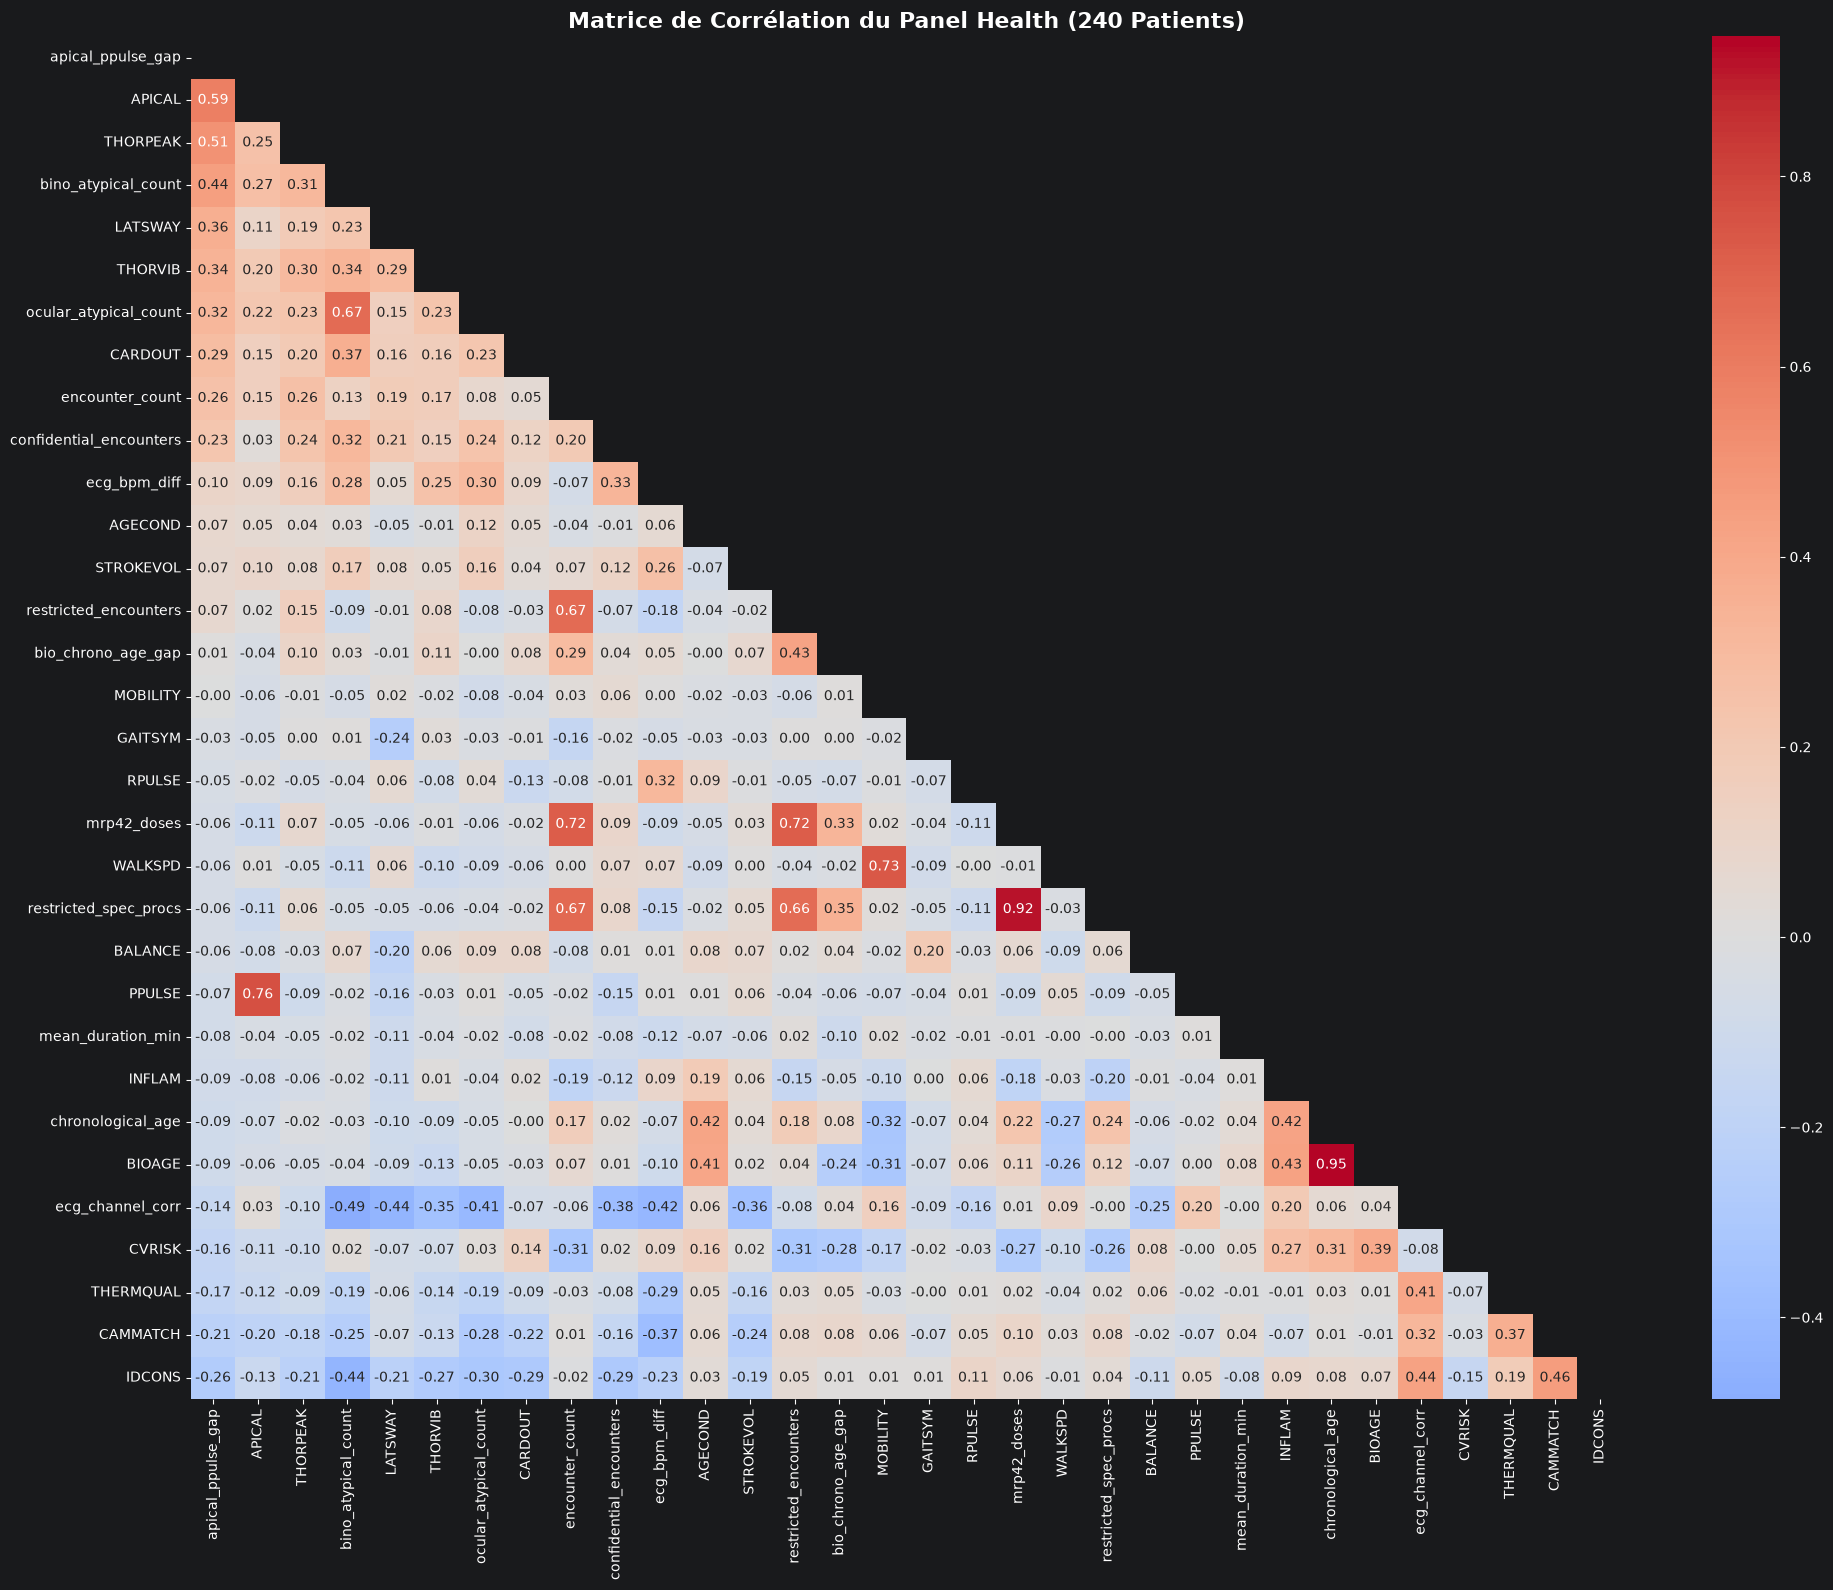

In [16]:
# AFFICHAGE DE LA MATRICE DE CORRÉLATION DU PANEL HEALTH
GROUPS = {
    "Cardiaque & Thorax (observations/ECG)": [
        "apical_ppulse_gap", "APICAL", "PPULSE", "RPULSE", "THORPEAK", "THORVIB",
        "CARDOUT", "STROKEVOL", "ecg_channel_corr", "ecg_bpm_diff"
    ],
    "Mobilité, Oculaire & Caméra (observations)": [
        "LATSWAY", "BALANCE", "MOBILITY", "GAITSYM", "WALKSPD",
        "ocular_atypical_count", "bino_atypical_count", "CAMMATCH", "THERMQUAL", "IDCONS"
    ],
    "Âge Biologique & Protocole MRP-42 (procedures/admin)": [
        "bio_chrono_age_gap", "BIOAGE", "chronological_age", "mrp42_doses",
        "restricted_spec_procs", "AGECOND", "CVRISK", "INFLAM"
    ],
    "Parcours Clinique (encounters)": [
        "restricted_encounters", "confidential_encounters", "encounter_count", "mean_duration_min"
    ]
}
ORDER = [c for cols in GROUPS.values() for c in cols]

corr = panel[ORDER].corr()
order = corr["apical_ppulse_gap"].sort_values(ascending=False).index
corr_ordered = corr.loc[order, order]
mask = np.triu(np.ones_like(corr_ordered, dtype=bool))

plt.figure(figsize=(20, 16))
sns.heatmap(corr_ordered, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de Corrélation du Panel Health (240 Patients)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

2.3. ACP (PCA), Clustering K-Means et Fouille Textuelle TF-IDF 

Pour valider mathématiquement les deux blocs observés dans la matrice de corrélation, nous appliquons :

Une ACP (PCA) et un Clustering KMeans sur les constantes physiologiques des 240 patients.
Une vectorisation TF-IDF et similarité Cosinus sur les 30 rapports de clinical_notes.csv pour isoler les notes médicales anormales.


C:\Users\Proprietaire\anaconda3\envs\DataMining\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


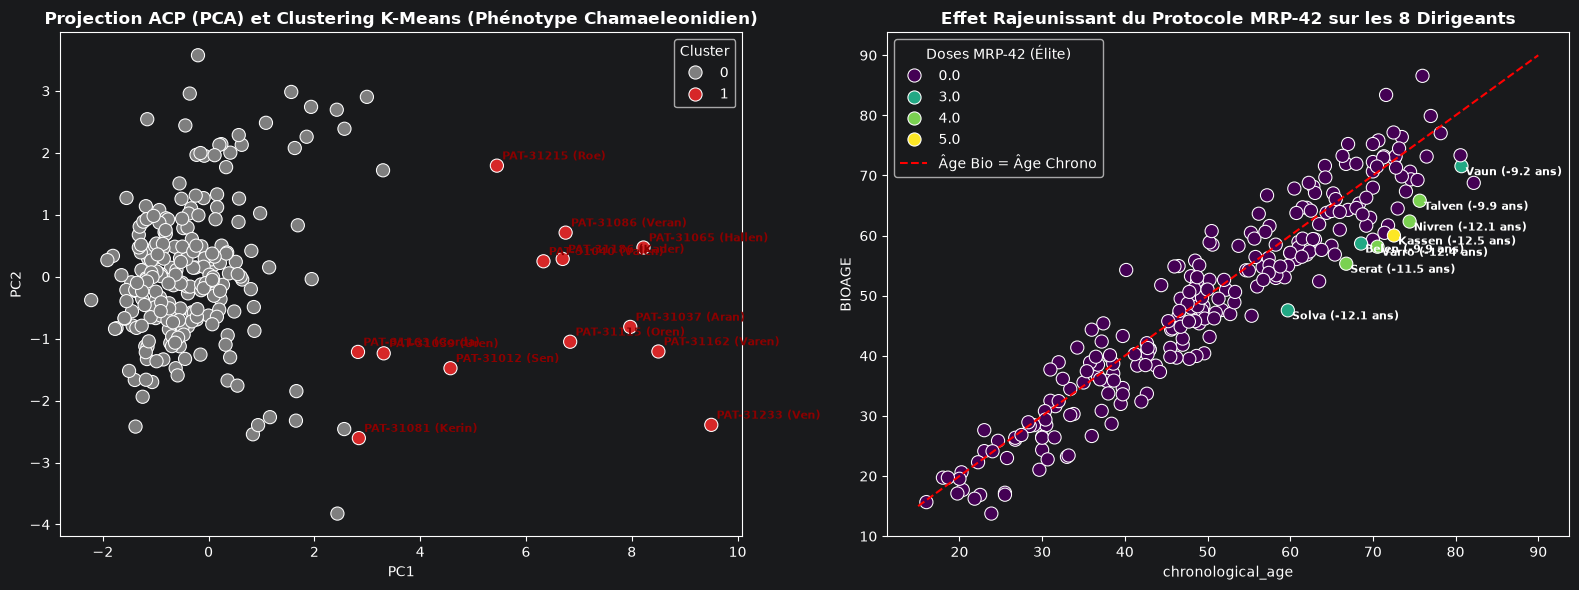

=== Les 4 Notes Cliniques Uniques (Outliers Textuels détectés par TF-IDF) ===


,document_id,patient_number,confidentiality_class,title,mean_cosine_sim
0,CLN-510027,PAT-31065,restricted,Targeted Thoracic Imaging Review,0.084714
2,CLN-510025,PAT-31065,restricted,Restricted Phenotype and Public-Identity Resol...,0.085639
1,CLN-510055,PAT-31115,restricted,Consultation on Recurrent Capture Discrepancies,0.098741
3,CLN-510064,PAT-31012,confidential,Persistent Multisystem Follow-up,0.128059


In [17]:
# ACP (PCA), CLUSTERING K-MEANS ET VISUALISATION DES GROUPES DE PATIENTS

features_clust = [
    "apical_ppulse_gap", "THORPEAK", "THORVIB", "LATSWAY", "BALANCE",
    "CAMMATCH", "THERMQUAL", "IDCONS", "ocular_atypical_count", "bino_atypical_count"
]
X_raw = panel[features_clust].fillna(panel[features_clust].median())

# Centrage-réduction obligatoire avant ACP et K-Means (échelles différentes)
X_scaled = StandardScaler().fit_transform(X_raw)

# Projection ACP en 2 dimensions
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
panel["PC1"], panel["PC2"] = coords[:, 0], coords[:, 1]

# Clustering K-Means (2 clusters : Patients normaux vs Phénotype Atypique)
panel["Cluster"] = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_scaled)
if (panel["Cluster"] == 1).sum() > 50:
    panel["Cluster"] = 1 - panel["Cluster"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Projection PCA des 240 patients
sns.scatterplot(data=panel, x="PC1", y="PC2", hue="Cluster", palette={0: "#7f7f7f", 1: "#d62728"}, s=90, ax=axes[0])
for _, row in panel[panel["Cluster"] == 1].iterrows():
    axes[0].annotate(f"{row['patient_number']} ({row['family_name']})", (row["PC1"]+0.1, row["PC2"]+0.1), fontsize=8, fontweight="bold", color="darkred")
axes[0].set_title("Projection ACP (PCA) et Clustering K-Means (Phénotype Chamaeleonidien)", fontweight="bold")

# Graphique 2 : Rajeunissement biologique dû au protocole MRP-42
sns.scatterplot(data=panel, x="chronological_age", y="BIOAGE", hue="restricted_spec_procs", palette="viridis", s=90, ax=axes[1])
axes[1].plot([15, 90], [15, 90], "r--", label="Âge Bio = Âge Chrono")
for _, row in panel[panel["restricted_spec_procs"] > 0].iterrows():
    axes[1].annotate(f"{row['family_name']} (-{row['bio_chrono_age_gap']:.1f} ans)", (row["chronological_age"]+0.5, row["BIOAGE"]-1.5), fontsize=8, fontweight="bold")
axes[1].set_title("Effet Rajeunissant du Protocole MRP-42 sur les 8 Dirigeants", fontweight="bold")
axes[1].legend(title="Doses MRP-42 (Élite)")

plt.tight_layout()
plt.show()

# FOUILLE DE TEXTE (TF-IDF) SUR LES 30 NOTES CLINIQUES 

tfidf_mat = TfidfVectorizer(stop_words="english", max_features=500).fit_transform(df_notes["text"])
sim_mat = cosine_similarity(tfidf_mat)
df_notes["mean_cosine_sim"] = (sim_mat.sum(axis=1) - 1.0) / (len(df_notes) - 1)

print("=== Les 4 Notes Cliniques Uniques (Outliers Textuels détectés par TF-IDF) ===")
display(df_notes.sort_values("mean_cosine_sim")[["document_id", "patient_number", "confidentiality_class", "title", "mean_cosine_sim"]].head(4))

In [32]:
from pathlib import Path
OUTPUT_DIR = Path("../..") / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.tight_layout()

fig.savefig(OUTPUT_DIR / "pca_kmeans_et_bioage.png", dpi=300, bbox_inches="tight")


<Figure size 640x480 with 0 Axes>

In [42]:
anomalies1 = panel[panel["Cluster"]==1]
anomalies1 = anomalies1[["patient_number","family_name","given_name","bio_chrono_age_gap","apical_ppulse_gap","LATSWAY","ocular_atypical_count","bino_atypical_count"]]

anomalies2 = panel[panel["bio_chrono_age_gap"]<-7]
anomalies2 = anomalies2[["patient_number","family_name","given_name","bio_chrono_age_gap","apical_ppulse_gap","LATSWAY","ocular_atypical_count","bino_atypical_count"]]

anomalies = pd.concat([anomalies1,anomalies2])
print(anomalies.drop_duplicates())

    patient_number family_name given_name  bio_chrono_age_gap  \
11       PAT-31012         Sen      Amara            1.540000   
36       PAT-31037        Aran        Sel           -1.080000   
38       PAT-31039        Uren      Liora           -3.750000   
39       PAT-31040       Valen      Jonah            8.300000   
64       PAT-31065      Hallen      Corin            5.150000   
80       PAT-31081       Kerin       Orin            3.650000   
85       PAT-31086       Veran       Niko           -7.333333   
114      PAT-31115        Oren      Nadia            4.040000   
161      PAT-31162       Varen        Eli            6.266667   
162      PAT-31163       Corda       Gita           -3.950000   
185      PAT-31186       Kader      Soren            4.575000   
214      PAT-31215         Roe       Ilan            5.666667   
232      PAT-31233         Ven       Mara            0.900000   
8        PAT-31009       Garen      Zoren           -8.433333   
55       PAT-31056       

Partie 3 — Conclusions Générales et Interprétation du Dossier Health

L'analyse complète et le croisement interne des 7 jeux de données de data/health/ permettent d'établir quatre conclusions majeures :

Un bilan de nettoyage décisif :

La déduplication a éliminé 6 doublons exacts répartis dans les tables (PAT-31045, ENC-000846, ENC-000733, PRC-000263, OBS-0015195, OBS-0003236), fixant la cohorte réelle à 240 patients uniques et 1 067 consultations.

La fonction clean_numeric a permis de sauver 340 mesures numériques corrompues dans clinical_observations.csv (virgules décimales et unités concaténées), évitant une perte critique d'information.

L'harmonisation textuelle a corrigé les anomalies de casse et d'espaces multiples (ramenant par exemple encounter_type de 15 à 10 modalités réelles et supprimant la colonne vide superseded_document_id).

    Découverte n°1 — Le Cluster des 10 patients au phénotype « Chamaeleonidien » :

La Matrice de Corrélation, l'ACP et le Clustering K-Means isolent un groupe très spécifique de 10 patients (les index 0 à 9 de patient_administration.csv : PAT-31162 Eli Varen, PAT-31040 Jonah Valen, PAT-31115 Nadia Oren, PAT-31186 Soren Kader, PAT-31215 Ilan Roe, PAT-31233 Mara Ven, PAT-31065 Corin Hallen, PAT-31012 Amara Sen, PAT-31086 Niko Veran, PAT-31037 Sel Aran).

Ces individus partagent quatre traits biologiques non-humains fortement corrélés entre eux : 

Une double structure cardiaque contractile : Un écart massif entre le rythme apical et le pouls périphérique (apical_ppulse_gap = +22,36 bpm en moyenne contre +2,52 bpm chez les témoins), un pic thoracique secondaire élevé (THORPEAK = 57,31), et une désynchronisation entre les deux canaux ECG (ecg_channel_corr ) où la Transformée de Fourier (FFT) prouve l'existence de deux fréquences cardiaques fondamentales simultanées (confirmé textuellement par l'échographie thoracique CLN-510027).

Une locomotion de caméléon : Une démarche chaloupée à forte oscillation latérale (LATSWAY = 61,29 contre 31,12), mais avec un équilibre parfait (BALANCE = 80,99) et sans trouble neurologique ou vestibulaire (CLN-510064).

Une vision indépendante : Ils concentrent les suivis oculaires et binoculaires atypiques (OCULAR = atypical, BINOCOORD = atypical, corrélation ).

Une capacité de camouflage optique et thermique : Une chute anormale des scores de reconnaissance faciale caméra (CAMMATCH = 70,7 %), de stabilité thermique (THERMQUAL = 80,4 %) et de constance d'identité (IDCONS = 74,2 %), expliquée dans la note CLN-510055 par de brèves discontinuités du contour facial et un possible « contrôle délibéré de l'apparence ».

    Découverte n°2 — Le Protocole anti-âge MRP-42 administré aux 8 dirigeants humains :
    
La matrice de corrélation met en évidence un second bloc indépendant du premier : le nombre de doses du protocole MRP-42 (Targeted metabolic resilience administration, seul acte consommant les 50 lots matériels MTL-...) est fortement corrélé aux consultations secrètes restricted_encounters (), aux actes restricted_spec_procs () et au rajeunissement biologique bio_chrono_age_gap ().

Les 8 hauts dirigeants politiques et industriels (PAT-31221 Leora Kassen, PAT-31044 Tavian Serat, PAT-31174 Mirek Talven, PAT-31119 Celene Varro, PAT-31074 Oskar Nivren, PAT-31183 Adrienne Solva, PAT-31142 Rayan Belen, PAT-31099 Elira Vaun) reçoivent 3 à 5 injections chacun (30 doses au total), ce qui abaisse leur âge biologique estimé (BIOAGE) de 9,2 à 12,5 ans en dessous de leur âge chronologique réel (moyenne : -11,2 ans) ! À l'inverse, les 20 citoyens ordinaires ayant reçu une dose unique de test (research_restricted) ne présentent aucun rajeunissement significatif (+1,44 an).

Piste de croisement vers les autres dossiers (public_records & logistics) :

La note clinique CLN-510025 révèle que ces dossiers médicaux sous pseudonymes peuvent être reliés par résolution d'entités (tranche d'âge, région, clinique, dates de mandat) à des personnalités publiques comme Elias Voss, tandis que l'origine des 50 lots matériels MTL-... utilisés pour le protocole MRP-42 et le rôle des médecins LIC-VLN-MED-1002 et LIC-VLN-MED-1001 devront être tracés dans les dossiers logistics et public_records.
